# Stage 1 on the virtual NEOARM: today's session, rehearsed

This notebook runs **exactly the code you run at the microscope**:
- `stage1_acquire.py` (PyJEM calls only), against the virtual NEOARM through its PyJEM imitation;
- `stage1_analysis.py`, which turns the saved frames into the predictive model.

On the real microscope, replace the first code cell with `from PyJEM import TEM3, detector`;
everything else stays the same.

**Where the virtual microscope differs from the NEOARM:**
- its lens table differs: its 40k row is not the NEOARM's;
- its DIFF mode is designed on its hidden optics (camera lengths 15 cm to 1 m, IL1 weakened as on a
  JEOL), not copied from the NEOARM's DIFF table;
- lenses settle instantly (`settle_s=0`; use about 2 s on the real microscope);
- its camera image is mirrored relative to the column. The analysis has to find that out by
  itself.

The result we want is a **predictive model**: for any lens setting (IL1, IL2, IL3, PL1 DAC values)
in the explored range, and any change of the shift (CLA1) or tilt (CLA2) deflector, where the beam
goes on the camera. The last part checks it at lens settings the session never visited.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"
import shutil
from pathlib import Path

import numpy as np
import projector_figures as F
import stage1_acquire as S
import stage1_analysis as A
from temgym_core.virtual.pyjem import facade
from virtual_neoarm import REFERENCE_SPOT, build_virtual_neoarm

F.apply_style()
OUT = Path("../generated/stage1_virtual")
shutil.rmtree(OUT, ignore_errors=True)
OUT.mkdir(parents=True)

# 131 072 traced electrons per frame; 8x8 sub-samples per pixel keep sub-pixel spot positions
# (with 1, a 1 px diffraction spot locks to pixel centres)
scope, _, _ = build_virtual_neoarm(ray_sample_power=17, detector_samples_per_pixel=8)
TEM3, detector = facade(scope)        # on the microscope: from PyJEM import TEM3, detector

## 1. Set up (by hand on the real microscope)

The settings you choose at the console: HT, MAG mode, the 40k row, spot size, the condenser
aperture, and the camera's binning and exposure. Specimen out.

In [2]:
TEM3.HT3().SetHtValue(200e3)
eos = TEM3.EOS3()
eos.SelectFunctionMode(0)                      # MAG
S.select_magnification(eos, 40000.0)
eos.SelectSpotSize(REFERENCE_SPOT)
aperture = TEM3.Apt3(); aperture.SelectKind(1); aperture.SetSize(1)
camera = detector.Detector(detector.get_attached_detector()[0])
camera.set_detectorsetting({"BinningSize": 8, "ExposureTimeValue": 0.01e6})
print("HT", TEM3.HT3().GetHtValue(), "V |", eos.GetMagValue(), "| camera", camera.get_detectorsetting()["ImagingArea"])

HT 200000.0 V | [40000, 'X', 'X40000'] | camera {'X': 0, 'Y': 0, 'Width': 256, 'Height': 256}


## 2. Read every lens value

On the real microscope, do this in MAG mode, then again in DIFF mode, and compare. If only IL1–IL3
and PL1 change, DIFF mode only touches the lenses the model drives.

In [3]:
lenses = S.read_all_lenses(TEM3)
F.table(["lens", "DAC value (MAG)"], [[k, v] for k, v in lenses.items()])
LENS = TEM3.Lens3()
base = np.array([LENS.GetIL1(), LENS.GetIL2(), LENS.GetIL3(), LENS.GetPL1()], float)
print("40k row (IL1, IL2, IL3, PL1):", base)

| lens | DAC value (MAG) |
|---|---|
| CL1 | 30513 |
| CL2 | 32768 |
| CL3 | 32688 |
| CM | 50000 |
| OLc | 45818 |
| OLf | 39178 |
| OM | 32768 |
| OM2 | 32768 |
| IL1 | 46458 |
| IL2 | 46445 |
| IL3 | 39733 |
| IL4 | 32768 |
| PL1 | 24575 |
| PL2 | 32768 |
| PL3 | 32768 |
| function_mode | [0, 'MAG'] |

40k row (IL1, IL2, IL3, PL1): [46458. 46445. 39733. 24575.]


## 3. The diffraction setting: read it in DIFF mode

1. Switch to **DIFF**, and choose a camera length that keeps the gold rings on the camera: here
   80 cm, where Au(111) at 200 kV lands about 77 px from the centre.
2. Read **every** lens value again and compare with MAG. Only IL1–IL3 (and PL1) may differ; then
   DIFF touches only the lenses the model drives.
3. The diffraction setting is the four DIFF values of IL1, IL2, IL3, PL1. Go back to MAG.

Stage 1 sets these four values **in MAG with free-lens control**. The last lines check that this
"copy" puts the beam where DIFF mode itself does. On the virtual microscope that holds by
construction; on the NEOARM it is the check worth making.

(If DIFF mode cannot be read, `S.find_diffraction_il3` finds a diffraction setting by measurement:
it steps IL3 until a beam shift no longer moves the spot.)

In [4]:
eos.SelectFunctionMode(4)                                  # DIFF
for _ in range(20):                                         # step the selector to 80 cm
    if eos.GetMagValue()[0] >= 80:
        break
    eos.UpSelector()
print("DIFF,", eos.GetMagValue()[2])
in_diff = S.read_all_lenses(TEM3)
F.table(["lens", "MAG", "DIFF", ""], [[k, lenses[k], in_diff[k], "changed" if lenses[k] != in_diff[k] else ""]
                                      for k in lenses if k != "function_mode"])
diffraction = np.array([in_diff[k] for k in ("IL1", "IL2", "IL3", "PL1")], float)
print("diffraction setting (IL1, IL2, IL3, PL1):", diffraction)

DIFF, 80cm


| lens | MAG | DIFF |  |
|---|---|---|---|
| CL1 | 30513 | 30513 |  |
| CL2 | 32768 | 32768 |  |
| CL3 | 32688 | 32688 |  |
| CM | 50000 | 50000 |  |
| OLc | 45818 | 45818 |  |
| OLf | 39178 | 39178 |  |
| OM | 32768 | 32768 |  |
| OM2 | 32768 | 32768 |  |
| IL1 | 46458 | 26495 | changed |
| IL2 | 46445 | 33825 | changed |
| IL3 | 39733 | 54328 | changed |
| IL4 | 32768 | 32768 |  |
| PL1 | 24575 | 24575 |  |
| PL2 | 32768 | 32768 |  |
| PL3 | 32768 | 32768 |  |

diffraction setting (IL1, IL2, IL3, PL1): [26495. 33825. 54328. 24575.]


In [5]:
def beam_centre():
    frame = np.frombuffer(camera.snapshot_rawdata(), "<i4").reshape(256, 256).astype(float)
    return S.measure_spot(frame, 0.0)[0]

route_diff = beam_centre()                                  # in DIFF mode itself
eos.SelectFunctionMode(0)                                   # back to MAG, 40k row
for name, value in zip(("IL1", "IL2", "IL3", "PL1"), diffraction):
    LENS.SetFLCSw(S.FLC_IDS[name], 1); LENS.SetFLCAbs(S.FLC_IDS[name], int(value))
route_copy = beam_centre()                                  # the same four values, copied into MAG
for name in ("IL1", "IL2", "IL3", "PL1"):
    LENS.SetFLCSw(S.FLC_IDS[name], 0)
print(f"beam centre: DIFF mode {route_diff:.2f} px, copied into MAG {route_copy:.2f} px, "
      f"difference {abs(route_diff - route_copy):.3f} px")
print("back in", eos.GetFunctionMode()[1], eos.GetMagValue()[2])

beam centre: DIFF mode 0.02-0.00j px, copied into MAG 0.02-0.00j px, difference 0.000 px
back in MAG X40000


## 4. The two-minute deflector test

- **At the 40k row (in focus):** a pure **tilt** (CLA2) does not move the spot.
- **At the diffraction setting:** a pure **shift** (CLA1) does not move it.

Each check uses the other deflector as a reference.

In [6]:
test = S.deflector_test(TEM3, detector, OUT / "deflector_test", base, diffraction, units=10000, settle_s=0)
F.table(["setting", "CLA1 (shift) moves the beam", "CLA2 (tilt) moves the beam", "expected if pure"],
        [["40k row, in focus", f"{test['in focus']['CLA1 (shift)']:.2f} px", f"{test['in focus']['CLA2 (tilt)']:.3f} px", "CLA2 ≈ 0"],
         ["diffraction", f"{test['diffraction']['CLA1 (shift)']:.3f} px", f"{test['diffraction']['CLA2 (tilt)']:.2f} px", "CLA1 ≈ 0"]])

first frame: 256x256, read as <i4, values -8 to 4693 (if these look wrong, pass dtype='<u2' or similar)


| setting | CLA1 (shift) moves the beam | CLA2 (tilt) moves the beam | expected if pure |
|---|---|---|---|
| 40k row, in focus | 36.29 px | 0.003 px | CLA2 ≈ 0 |
| diffraction | 0.000 px | 14.54 px | CLA1 ≈ 0 |

## 5. Stage 1: one command

12 visits:
- the 8 lens settings, as multiples of the 40k row;
- the diffraction setting;
- setting 0 twice more (the wobble);
- setting 0 once with y kicks.

At each visit: a frame without a kick, a test kick, then a ± shift and a ± tilt scaled to about
50 px. A kick is halved if it cuts the beam at the frame edge. Everything is saved and the
microscope is restored at the end.

In [7]:
folder = S.run(TEM3, detector, OUT / "stage1", diffraction=diffraction, settle_s=0, max_units=(20000, 20000))
print("saved", len(list((folder / "frames").glob("*.npy"))), "frames to", folder)

settings [5, 6, 7]: a factor above the DAC range was replaced by its reciprocal


first frame: 256x256, read as <i4, values -7 to 18 (if these look wrong, pass dtype='<u2' or similar)


visit 1/12 (setting 0, x kicks) done


visit 2/12 (setting 1, x kicks) done


visit 3/12 (setting 2, x kicks) done


visit 4/12 (setting 3, x kicks) done


... (5 outputs left out)

visit 10/12 (setting diffraction, x kicks) done


visit 11/12 (setting 0, x kicks) done


visit 12/12 (setting 0, y kicks) done


saved 111 frames to ../generated/stage1_virtual/stage1


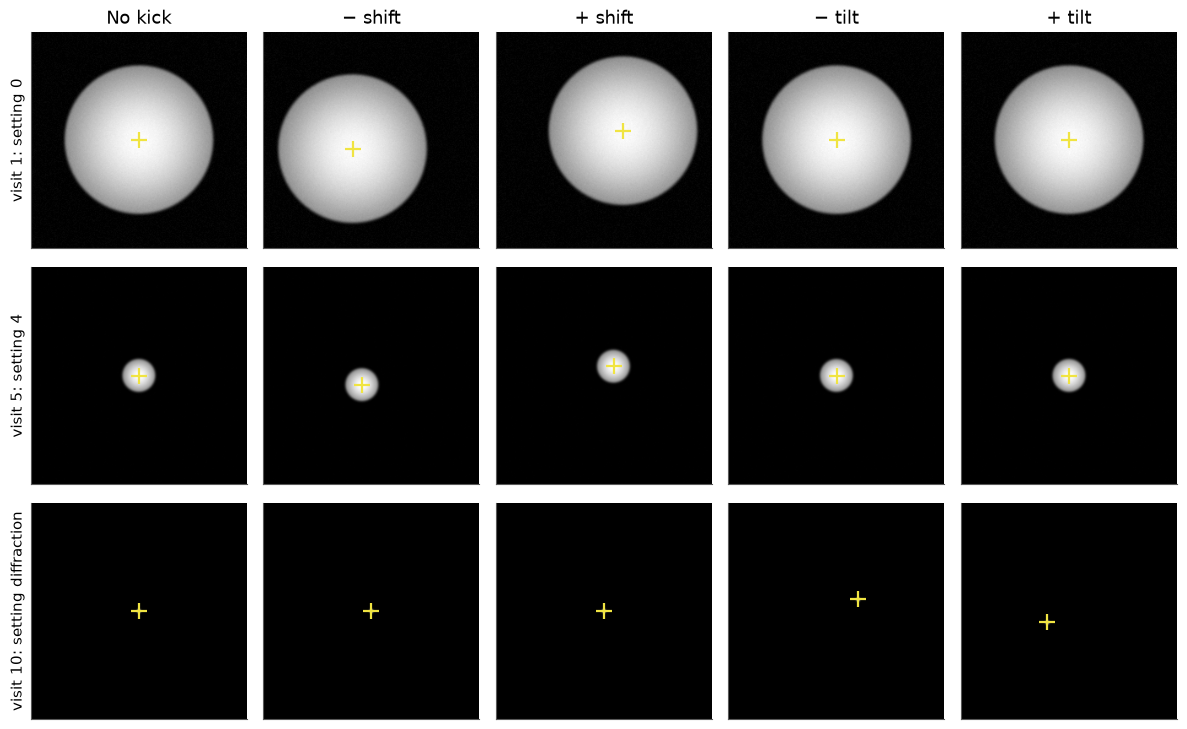

In [8]:
F.session_frames(folder, visits=(0, 4, 9))

## 6. The predictive model

`fit_session` measures every frame's centre, takes half of each ± difference, estimates the wobble
from the three visits to setting 0, and fits.

**Two choices are made from the data, not assumed:**
- **Handedness:** the camera image may be mirrored relative to the column, and the deflector's y
  axis may be mirrored against its x axis. All four combinations are fitted; the one at the noise
  level wins.
- **Deflectors:** pure shift and tilt, unless treating each deflector as a mix of both lowers χ²
  by more than chance would.

In [9]:
model = A.fit_session(folder)
F.table(["", "result"], [
    ["camera image mirrored", model["mirrored"]],
    ["deflector y axis flipped", model["y_flipped"]],
    ["deflectors", model["deflectors"]],
    ["beam-position wobble (from the repeats)", f"{model['wobble_px']:.3f} px ({model['wobble_dof']} degrees of freedom)"],
    ["χ²/dof", f"{model['chi2'] / model['dof']:.2f}"]])

  camera mirrored False y deflector flipped False: chi2/dof 3.51e+06


  camera mirrored False y deflector flipped True : chi2/dof 2.62e+06


  camera mirrored True  y deflector flipped False: chi2/dof 0.519


  camera mirrored True  y deflector flipped True : chi2/dof 2.24e+06


  deflectors: pure (chi2 drop from fitting the mixing: 0.6, chance level 15.1)


  worst-fitting measurements: visit 11 (0) shift 0.009 px, visit 6 (0) tilt 0.008 px, visit 11 (0) tilt 0.007 px


|  | result |
|---|---|
| camera image mirrored | True |
| deflector y axis flipped | False |
| deflectors | pure |
| beam-position wobble (from the repeats) | 0.008 px (8 degrees of freedom) |
| χ²/dof | 0.46 |

**Reading χ².** χ²/dof compares the misfit with the wobble measured from the repeats at
setting 0. A value far above 1 means some measurements disagree with the model by more than
the beam wobbles, by a repeatable amount the repeats cannot see. The "worst-fitting
measurements" line above shows which ones.

On the virtual NEOARM χ²/dof is about 0.5: the model fits to the wobble. (An earlier version of
this rehearsal had χ²/dof in the hundreds: the virtual camera binned rays to whole pixels, and the
1 px diffraction spot locked to pixel centres. A real camera can do the same with a spot of a
pixel or two, so keep the spot several pixels wide.) On the real microscope the worst-fit line
points at visits to look at: a beam cut by the frame edge, a lens that had not settled, a spot
too small for its pixels, or a beam whose shape changed.

What matters for a predictive model is the next test.

## 7. Is it predictive? Check at lens settings the session never visited

Eight new lens settings, each a blend of three of the nine (so between measured settings,
but never visited), with fixed ± shift and tilt changes. The
model predicts each beam move before it is measured. At the real microscope this is the test to
run once the model exists.

first frame: 256x256, read as <i4, values -8 to 16 (if these look wrong, pass dtype='<u2' or similar)


  dropped (beam cut by the frame edge): visit 3 shift


| setting | kick | measured (px) | predicted (px) | error (px) |
|---|---|---|---|---|
| check 0 | shift | 14.92+9.14j | 14.92+9.14j | 0.001 |
| check 0 | tilt | -3.57-2.19j | -3.57-2.19j | 0.003 |
| check 1 | shift | 13.42+4.78j | 13.42+4.78j | 0.002 |
| check 1 | tilt | -0.50-0.17j | -0.50-0.18j | 0.003 |
| check 2 | tilt | -1.15-0.50j | -1.15-0.51j | 0.009 |
| check 3 | shift | 10.01+6.91j | 10.01+6.90j | 0.002 |
| check 3 | tilt | -0.78-0.54j | -0.78-0.54j | 0.001 |
| check 4 | shift | 18.28+11.36j | 18.27+11.37j | 0.005 |
| check 4 | tilt | -1.40-0.87j | -1.39-0.87j | 0.001 |
| check 5 | shift | 8.91+6.67j | 8.91+6.67j | 0.001 |
| check 5 | tilt | -0.07-0.05j | -0.07-0.05j | 0.002 |
| check 6 | shift | 11.06+8.04j | 11.06+8.04j | 0.001 |
| check 6 | tilt | -0.24-0.18j | -0.24-0.18j | 0.002 |
| check 7 | shift | 14.39+10.54j | 14.39+10.55j | 0.003 |
| check 7 | tilt | -0.08-0.06j | -0.08-0.06j | 0.003 |

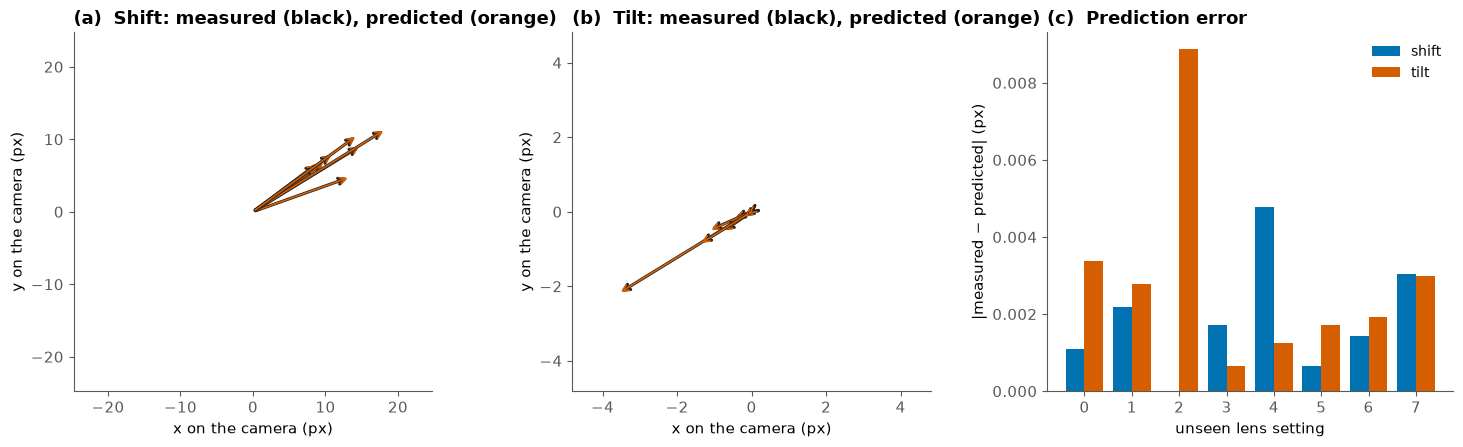

In [10]:
import json
settings = np.array(list(json.loads((folder / "plan.json").read_text())["settings"].values()))
rng = np.random.default_rng(7)
# blends of two or three of the nine settings: between measured settings, never visited themselves
weights = [rng.dirichlet(np.ones(3)) for _ in range(8)]
unseen = np.round([w @ settings[rng.choice(len(settings), 3, replace=False)] for w in weights])
check = S.check_run(TEM3, detector, OUT / "check", unseen, offsets=(10000, 10000), settle_s=0)
rows = A.compare(model, check)
F.table(["setting", "kick", "measured (px)", "predicted (px)", "error (px)"],
        [[r["setting"], r["kind"], f"{r['measured']:.2f}", f"{r['predicted']:.2f}", f"{r['error']:.3f}"] for r in rows])
F.prediction_check_figure(rows)

## What to bring back from the real session

- **The stage-1 folder:** frames, `log.json`, `plan.json`, `state_before.json`.
- **The lens readout** in MAG and in DIFF mode.
- **The deflector test result.**
- **If there was time,** a `check_run` folder at new lens settings.

`A.fit_session(folder)` then gives the model, and `A.compare(model, check_folder)` tells you
whether it predicts the real microscope.